
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma $f=-kx$. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### sin fuerza externa y regímen subamortiguado

In [2]:
# Parámetros de la simulación
rng = np.random.default_rng(42)


gamma = 1.0 # fricción
kBT = 1.0  # temperatura
D = kBT / gamma 
k = 3.0 # constante de restauración

dt = 0.005 # incremento temporal 
tmax = 10 # tiempo máximo 
N = int(tmax / dt) # número de puntos 
t = np.arange(N + 1) * dt # puntos de tiempo

In [3]:
# simulamos 4 partículas diferentes 
n_trayectorias = 5

# Cada fila representa una trayectoria
X = np.zeros((n_trayectorias, N + 1))

# Incrementos de Wiener: cada incremento tiene distribución N(0, dt)
''' Para cada trayectoria se genera una distribución de puntos gaussiana
para los N puntos. Con esto calcuamos directamente el incremento al multiplicar por dt'''
dW = np.sqrt(dt) * rng.normal(0,1,size=(n_trayectorias, N))

# Movimiento browniano: se actualizan las trayectorias 
dX = np.sqrt(2 * D) * dW

# guardar la evolución de las 5 trayectorias 
# con cumsum se suman los incrementos aleatorios para obtener la posición acumulada al final
X[:, 1:] = np.cumsum(dX, axis=1)


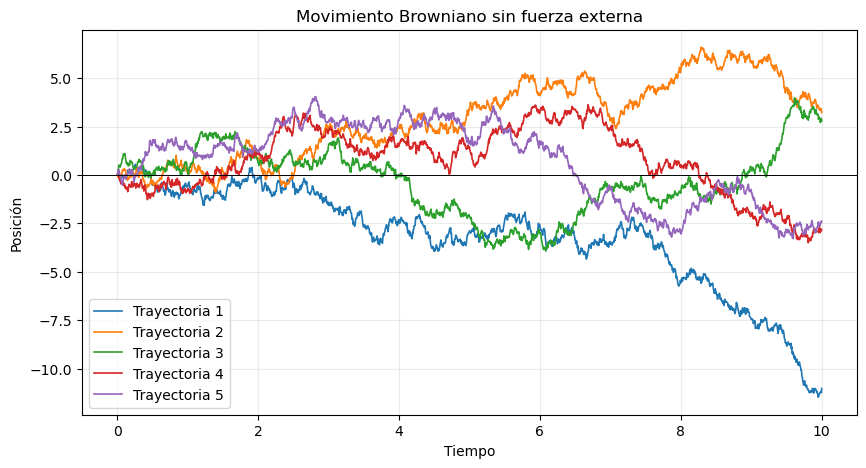

In [4]:
# Visualización
plt.figure(figsize=(10, 5))

for i in range(n_trayectorias):
    plt.plot(t, X[i], linewidth=1.2, label=f"Trayectoria {i+1}")

plt.title("Movimiento Browniano sin fuerza externa")
plt.xlabel("Tiempo")
plt.ylabel("Posición")
plt.legend()
plt.grid(alpha=0.25)
plt.axhline(0, color="black", linewidth=0.7)
plt.show()


Cada partícula experiemnta fluctuaciones aleatorias debidas al ruido térmico.Las posiciones acumulan incrementos aleatorios en la posición  debido a la la dependencia de la varianza con el tiempo. Sin embargo, el valor medio de la posición (promediando
sobre todas las partículas) permence en su posición inicial.

### Con fuerza externa

In [5]:
# Parámetros

n_particulas = 5  #simulamos 5 trayectorios 

# Posiciones iniciales
X_f = np.zeros((n_particulas, N + 1))
#X_f[:, 0] = rng.uniform(-3, 3, n_particulas) # si queremos dar una posición inicial diferente de 0 

# Evolución estocástica
for n in range(N):
    ruido = np.sqrt(2 * D * dt) * rng.normal(0,1,size=n_particulas)
    fuerza = - k * X_f[:, n] * dt/gamma 
    X_f[:, n + 1] = X_f[:, n] + fuerza + ruido

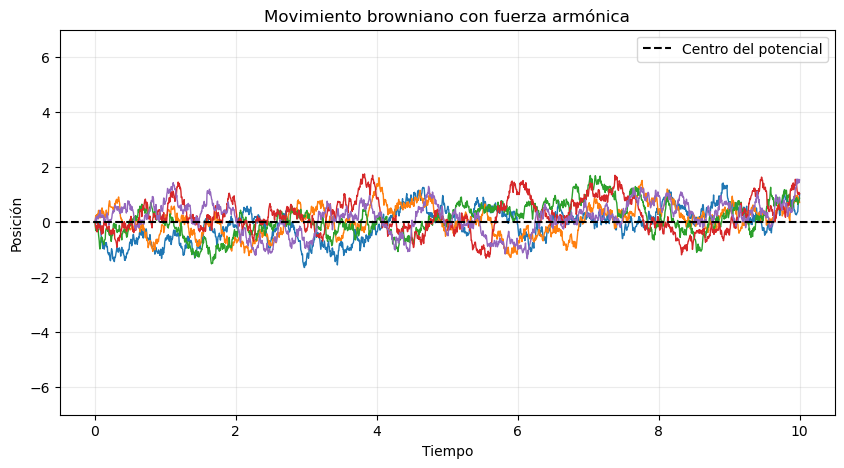

In [6]:
# Graficar trayectorias
plt.figure(figsize=(10, 5))
plt.title('Movimiento Browniano con fuerza Armónica')
for i in range(n_particulas):
    plt.plot(t, X_f[i], linewidth=1)

plt.axhline(0, color="black", linestyle="--",
            label="Centro del potencial")

plt.xlabel("Tiempo")
plt.ylabel("Posición")
plt.title("Movimiento browniano con fuerza armónica")
plt.legend()
plt.grid(alpha=0.25)
plt.ylim(-7,7)
plt.show()

Las partículas comienzan en posciciones distintas y la fuerza restauradora tiende a llevarlas a su posición de equilibrio en $x = 0$.  Sin embargo, el ruido contínua presente y cambia de forma aleatoria las posiciones. Estadísticamente, las trayectorias quedan confinadas al rededor de la posición de equilibrio. 

## Modelo de Langevin completo 

Ahora consideremos también el efecto de la inercia sin fuerza externa. En este caso, la ecuación del movimiento Browniano es la descrita anteriormente: 

\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}


Usando el método de Euler-Maruyama obtenemos que

\begin{equation}
\begin{aligned}
x_{n+1} &= x_n + v_n \Delta t, \\
v_{n+1} &= v_n - \frac{\gamma}{m} v_n \Delta t + \frac{\sqrt{2 \gamma k_B T}}{m} \sqrt{\Delta t} Z_n
\end{aligned}
\end{equation}

Aquí el ruido modifica directamentela velocidad,mientras que la fricción tiende a disipar el movimiento. La posción de la partícula depende directamente de esta velocidad.

In [7]:
# Parámetros de la simulación


gamma = 1.0 # fricción
kBT = 1.0  # temperatura
D = kBT / gamma 
m = 5.0 # masa de la partícula

dt = 0.005 # incremento temporal 
tmax = 30 # tiempo máximo 
N = int(tmax / dt) # número de puntos 
t = np.arange(N + 1) * dt # puntos de tiempo

In [8]:
# Posición y velocidad iniciales para 5 partículas
X_in = np.zeros((n_particulas, N + 1))
V_in =np.zeros((n_particulas, N + 1))

X_in[:, 0] = np.linspace(-2, 2, n_particulas)
V_in[:, 0] = 1.0  # Velocidad inicial igual para todas


# método de Langevin
for n in range(N):
    Z = rng.normal(0,1,size=n_particulas)
    
    X_in[:, n + 1] = X_in[:, n] + V_in[:, n] * dt
    V_in[:,n + 1] = (V_in[:, n]- (gamma / m) * V_in[:, n] * dt + np.sqrt(2 * gamma * kBT) / m * np.sqrt(dt) * Z)


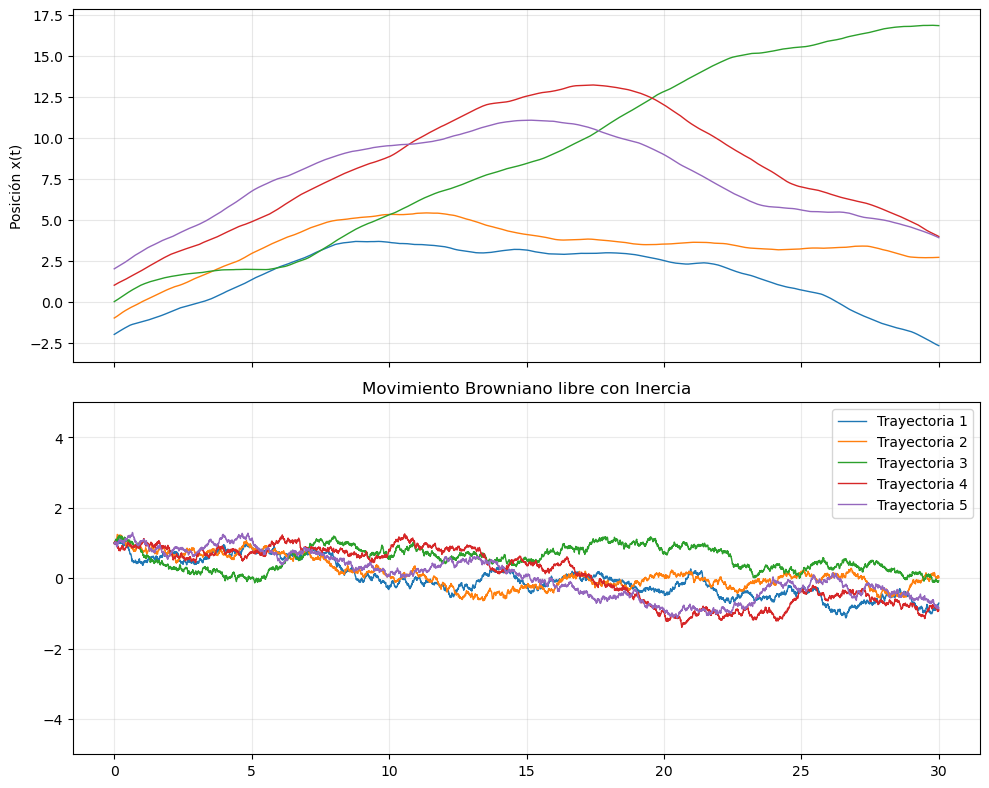

In [9]:
# Graficar trayectorias
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
plt.title('Movimiento Browniano libre con Inercia')

for i in range(n_particulas):
    ax[0].plot(t, X_in[i], linewidth=1, label=f"Trayectoria {i+1}")
    ax[0].set_ylabel("Posición x(t)")
    ax[0].grid(alpha=0.3)

    ax[1].plot(t, V_in[i], linewidth=1, label=f"Trayectoria {i+1}")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.ylim(-5,5)
plt.show()

Las 5 partículas comienzan en posiciones iniciales diferentes y presentan, durante un intervalo inicial, una tendencia de desplazamiento sostenido. Esto se debe al comportamiento balísitico que aproximadamente tienen las partículas: debido a la incercia, la velocidad inicial conserva partcialmente su valor inicial durante un tiempo del orden de $\tau_m = m / \gamma$. A tiempos muy grandes, la fricción y el ruido modifican las velocidades y las trayectorias se dispersan libremente (no hay fuerza restauradora). La velocidad muestra fluctuaciones al rededor del cero a medida que avanza el tiempo y pierde la memoria de su condición inicial.

# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [10]:
# Gaussiana objetivo
mu = 0.0
varianza = 1.0

# densidad de probabilidad 
def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )
# score de la distribución 
def score(x):
    return -(x - mu) / varianza

In [11]:
rng = np.random.default_rng(42)

# simulamos 200 trayectorias 
n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x_lgv = np.zeros((n_trayectorias, n_pasos + 1))
t = np.arange(n_pasos+1 ) * dt

In [12]:
# Todas las trayectorias comienzan en cero
x_lgv[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()
        
        x_lgv[k, j + 1] = (x_lgv[k, j] + dt * score(x_lgv[k, j]) + np.sqrt(2 * dt) * ruido)

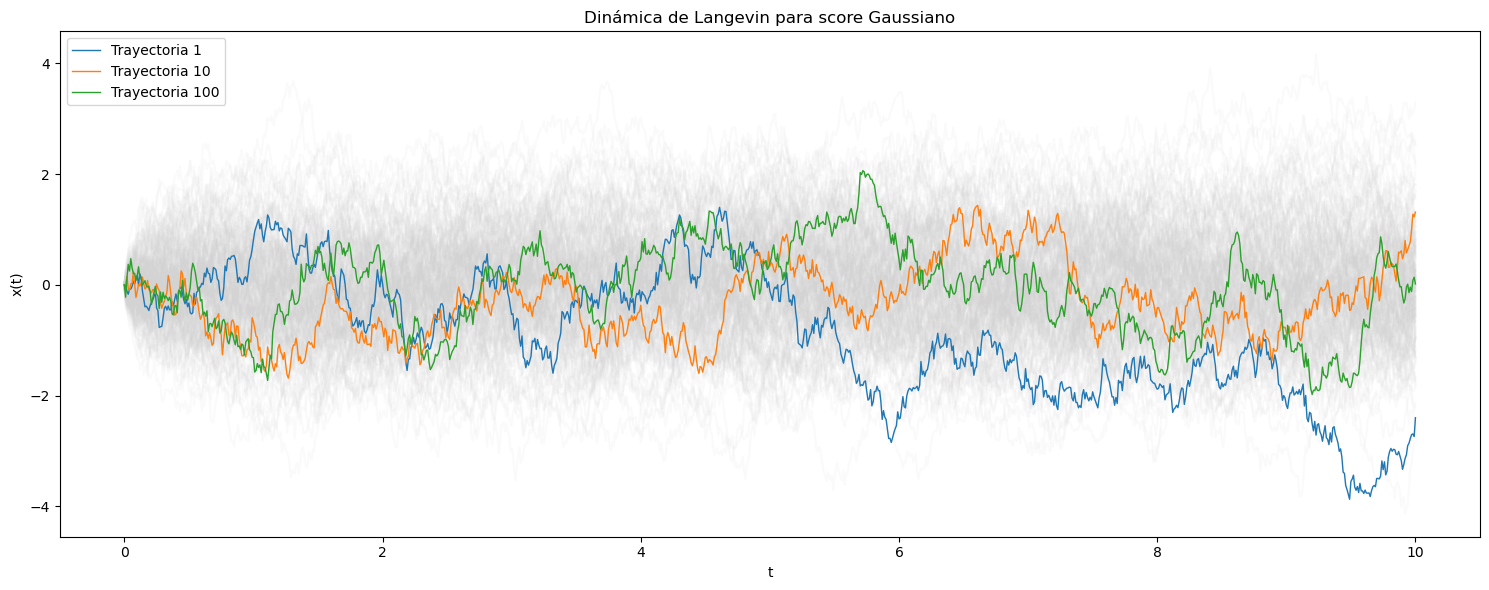

In [13]:
plt.figure(figsize=(15, 6))
plt.title('Dinámica de Langevin para score Gaussiano')
plt.plot(t, x_lgv.T, color='lightgray', alpha=0.1)
plt.plot(t, x_lgv[1], linewidth=1.0, label=f"Trayectoria {1}")
plt.plot(t, x_lgv[10], linewidth=1.0, label=f"Trayectoria {10}")
plt.plot(t, x_lgv[100], linewidth=1.0, label=f"Trayectoria {100}")
plt.xlabel('t')
plt.ylabel('x(t)')
plt.legend()
plt.tight_layout()
plt.show()

## Comparación muestras vs Gaussiana objetivo

In [14]:
x = np.concat(x_lgv)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


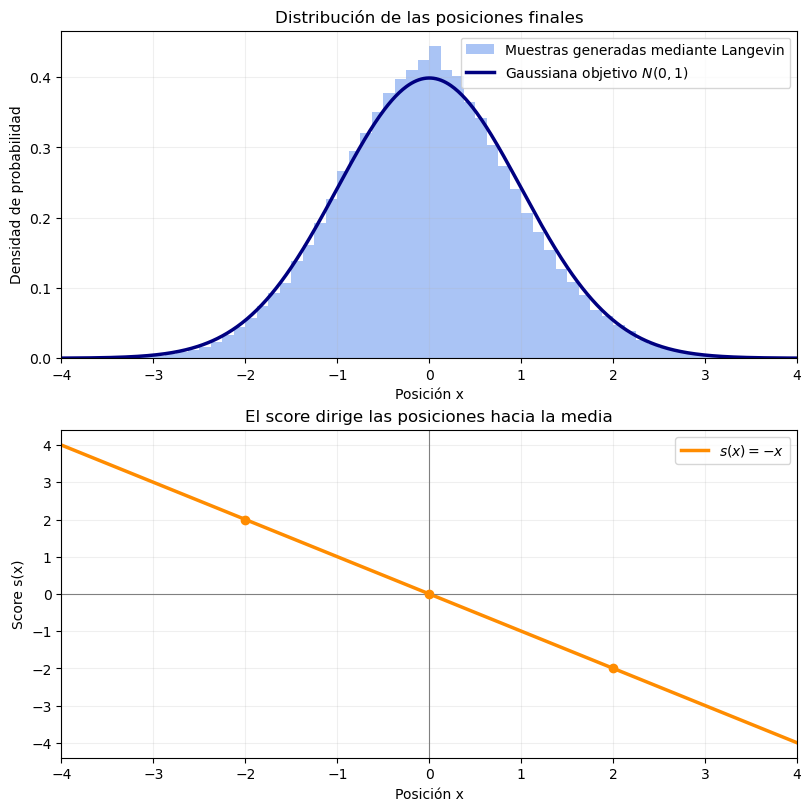

In [15]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

Las muestras generadas mediante la dinámica de Lagevin mediante scores coinciden bastante bien con la densidad gaussiana $p(x)$.

El campo de score $s(x) = - x$ es positivo  para $x < 0$ y negativo para $x > 0$, por lo que tiene el efecto de siempre llevar las posiciones hacia $\mu = 0 $. 

# Tarea

Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

Supongamos que las partículas en el equilibrio tienen una distribución Gaussiana de media $\vec{\mu} = (0, 0)$ y $\Sigma = I $. 

La densidad de probabilidad es 

$$ p(\vec{x})  = \frac{1}{2 \pi} \exp{\left ( - \frac{x_1 ^2 + x_2 ^2}{2} \right)} $$

Con $\vec{x} = (x_1, x_2)$. El campo de socre queda derminado por  

$$ s(\vec{x}) = \nabla_x \log p(\vec{x}) $$

lo cual nos da directamente que 

$$ s(\vec{x}) = - \vec{x} $$


Es decir, en cada punto $(x_1, x_2)$ el campo apunta hacia el origen. Y usamos la actualización numérica con la aproximación de Euler - Maruyama

$$ \mathbf{X}_{n+1} = \mathbf{X}_n +\mathbf{s}_\theta(\mathbf{X}_n)\Delta t + \sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n $$



In [16]:
# Parámetros de la simulación
rng = np.random.default_rng(42)

N = 1000         # Número de partículas
dt = 0.01           # Paso temporal
T = 20           # Tiempo total

n_steps = int(T / dt)

In [17]:
# Inicialización: distribución uniforme en el plano
X0 = rng.uniform(-4, 4, size=(N, 2))
X = X0.copy()

# Guardamos las trayectorias de cinco partículas
indices = np.arange(5)
trajectories = np.zeros((n_steps + 1, 5, 2))
trajectories[0] = X[indices]

# Dinámica de Langevin: score(x) = -x
for n in range(n_steps):
    ruido = rng.normal(size=(N, 2))
    X += -X * dt + np.sqrt(2 * dt) * ruido
    trajectories[n + 1] = X[indices]

# Estadísticas finales
mean_final = np.mean(X, axis=0)
cov_final = np.cov(X, rowvar=False)

print("Media final:")
print(mean_final)

print("\nCovarianza final:")
print(cov_final)


Media final:
[-0.00868875  0.00105633]

Covarianza final:
[[ 0.97163856 -0.02683781]
 [-0.02683781  0.95270394]]


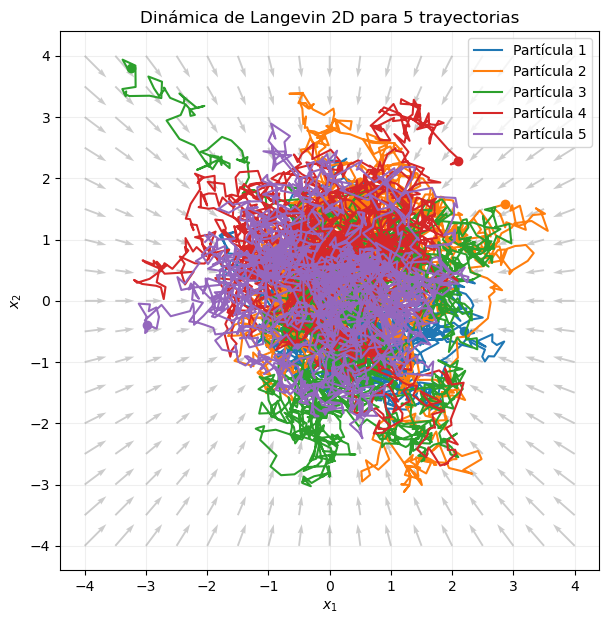

In [22]:
# Gráfica para 5 trayectorias 
grid = np.linspace(-4, 4, 17)
xx, yy = np.meshgrid(grid, grid)

fig, ax = plt.subplots(figsize=(7, 7))

ax.quiver(xx, yy, -xx, -yy, alpha=0.2)

for i in range(5):
    path, = ax.plot(trajectories[:, i, 0], trajectories[:, i, 1], label=f"Partícula {i+1}")
    c = path.get_color()

    ax.scatter(*trajectories[0, i], color=c, marker="o", zorder=2) # posición inicial 
    ax.scatter(*trajectories[-1, i], color=c,  marker="x", zorder=2) #posición final

ax.set_title("Dinámica de Langevin 2D para 5 trayectorias")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend()
ax.set_aspect("equal")
ax.grid(alpha=0.2)
plt.show()

In [ ]:
# media (valores esperados: 0, 0)
np.mean(trajectories[:, -1, :], axis=0)

array([-0.08980983,  0.20387752])

In [23]:
# covarianza (valores esperados en la diagonal 1, 0 por fuera)
np.cov(trajectories[:, -1, :].T)

array([[ 0.99071964, -0.09220802],
       [-0.09220802,  0.85203149]])

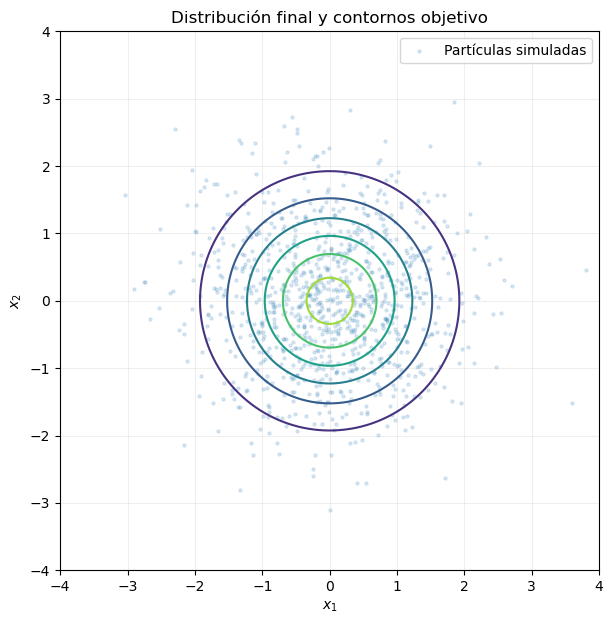

In [24]:
# Gaussiana objetivo vs Distribución 

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(X[:, 0], X[:, 1], s=5, alpha=0.15, label="Partículas simuladas")


# Contornos de la densidad gaussiana objetivo
g = np.linspace(-4, 4, 150)
gx, gy = np.meshgrid(g, g)
p = np.exp(-(gx**2 + gy**2) / 2) / (2 * np.pi)

ax.contour(gx, gy, p, levels=6)
ax.set_title("Distribución final y contornos objetivo")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)
plt.show()
